# TP Integrador — Dataset Nursery

In [129]:
# @title Imports y parámetros
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import warnings
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline   # igual al Pipeline de sklearn, pero acepta pasos de balanceo
warnings.filterwarnings("ignore")   # oculta los avisos de convergencia del MLP
N_SPLITS= 5      # cantidad de particiones de la validación cruzada
TEST_SIZE= 0.2   # 80% train - 20% test en cada partición
# carpeta raíz del proyecto (funciona sin importar desde dónde se ejecute el notebook)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "datos.py").exists())
RUTA_DATOS = RAIZ / "data" / "raw" / "Datos.txt"

# para poder importar desde src/
sys.path.append(str(RAIZ / "src"))
from datos import cargar_datos
import AA_utils

SEMILLA = 42  # para que los resultados sean reproducibles

In [130]:
# @title Cargar dataset
columnas= ['parents', 'has_nurs', 'form', 'children', 'housing', 'finance', 'social', 'health', 'clase']
df= pd.read_csv(RUTA_DATOS, header=None, names=columnas, dtype=str)

print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")
print("\nValores nulos por columna:")
print(df.isnull().sum())

display(df.head())
display(df.describe())   # count / unique / top / freq de cada atributo (todos son nominales)

Cantidad de registros: 12960
Cantidad de columnas: 9

Valores nulos por columna:
parents     0
has_nurs    0
form        0
children    0
housing     0
finance     0
social      0
health      0
clase       0
dtype: int64


,parents,has_nurs,form,children,housing,finance,social,health,clase
0,usual,proper,complete,1,convenient,convenient,nonprob,recommended,recommend
1,usual,proper,complete,1,convenient,convenient,nonprob,priority,priority
2,usual,proper,complete,1,convenient,convenient,nonprob,not_recom,not_recom
3,usual,proper,complete,1,convenient,convenient,slightly_prob,recommended,recommend
4,usual,proper,complete,1,convenient,convenient,slightly_prob,priority,priority


,parents,has_nurs,form,children,housing,finance,social,health,clase
count,12960,12960,12960,12960,12960,12960,12960,12960,12960
unique,3,5,4,4,3,2,3,3,5
top,usual,proper,complete,1,convenient,convenient,nonprob,recommended,not_recom
freq,4320,2592,3240,3240,4320,6480,4320,4320,4320


### Qué vemos en la carga

- Hay 12.960 registros y 9 columnas (8 atributos más `clase`), sin valores nulos.
- En los 8 atributos, la `freq` del valor más frecuente es exactamente 12.960 / `unique`: cada valor aparece la misma cantidad de veces.
- El producto de los `unique` de los atributos da 3·5·4·4·3·2·3·3 = 12.960, igual que la cantidad de registros. Coincide con la descripción del dataset: las instancias cubren todo el espacio de atributos, cada combinación una vez.
- Por eso ningún atributo está desbalanceado, y lo que hay que analizar es cómo se relaciona cada uno con la clase.
- `clase` es la única variable despareja: tiene 5 valores y `not_recom` aparece 4.320 veces, cuando un reparto parejo daría 2.592.

In [131]:
# @title Distribución de la clase
print(df['clase'].value_counts())

fig= px.histogram(df, x='clase', title='Distribución de la clase (dataset completo)',
                  category_orders={'clase': df['clase'].value_counts().index.tolist()})
fig.show()

clase
not_recom     4320
priority      4266
spec_prior    4044
very_recom     328
recommend        2
Name: count, dtype: int64


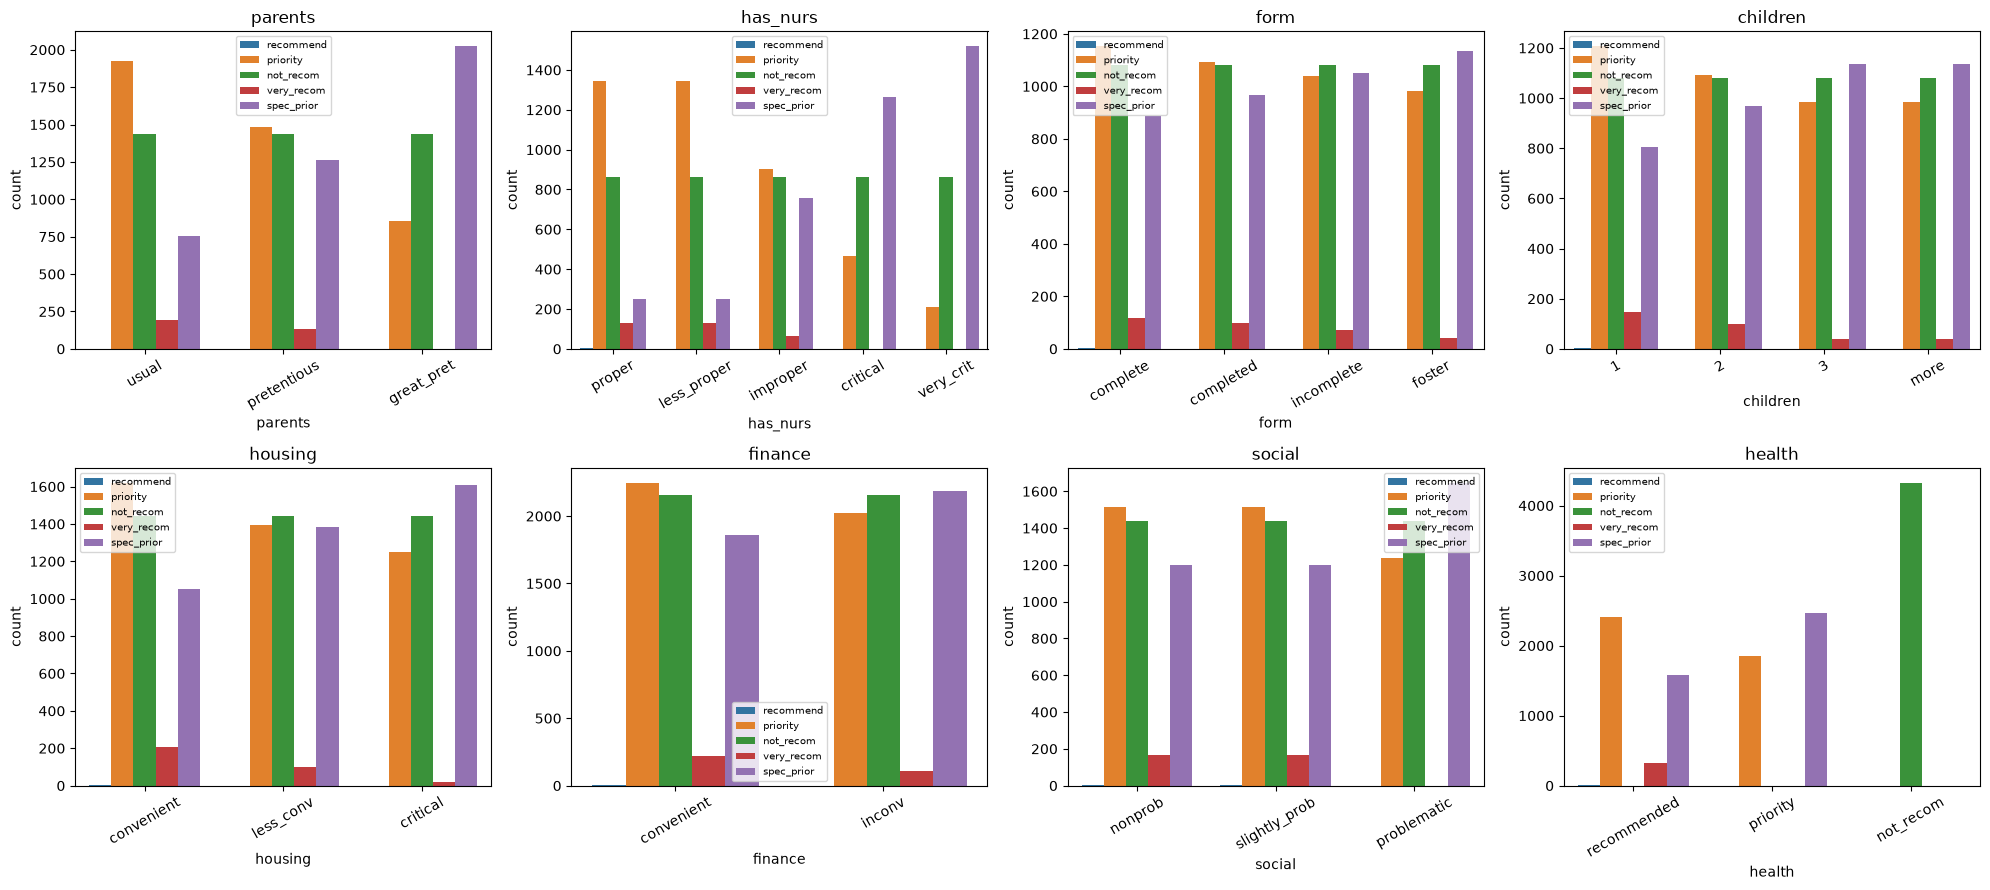

In [132]:
# @title Distribución de cada atributo según la clase
fig, axes= plt.subplots(2, 4, figsize=(20, 9))
for col, ax in zip(columnas[:-1], axes.ravel()):
    sns.countplot(data=df, x=col, hue='clase', ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [133]:
# @title ¿Por qué no usar la clase "not_recom"?
# Tabla cruzada entre el atributo health y la clase
tabla= pd.crosstab(df['health'], df['clase'])
display(tabla)
fig= px.imshow(tabla, text_auto=True, color_continuous_scale='Blues',
               title='health vs clase')
fig.show()
# Las 4320 muestras con health = not_recom son EXACTAMENTE las de la clase not_recom.
# Un único atributo separa perfectamente esa clase: el problema not_recom vs very_recom
# sería trivial (100% de acierto). Por eso se elige la siguiente clase mayoritaria: "priority"

clase,not_recom,priority,recommend,spec_prior,very_recom
health,,,,,
not_recom,4320,0,0,0,0
priority,0,1854,0,2466,0
recommended,0,2412,2,1578,328


### Qué vemos en el cruce de `health` con la clase

- Las 4.320 filas con `health = not_recom` son exactamente las 4.320 de la clase `not_recom`. Esa clase queda definida por una sola columna.
- Si comparáramos `not_recom` contra `very_recom`, cualquier modelo separaría todo con esa regla y no habría nada que comparar.
- `very_recom` solo aparece con `health = recommended`.
- Por eso elegimos `priority` como clase mayoritaria: no queda definida por un único atributo y comparte `health = recommended` con `very_recom` (2.412 filas de `priority` y 328 de `very_recom`).

In [134]:
# @title Selección del subconjunto
df_bin= df[df['clase'].isin(['priority', 'very_recom'])].copy()

print(f"Cantidad de registros: {df_bin.shape[0]}")
print(df_bin['clase'].value_counts())
print(f"\nRelación de desbalance: {(df_bin['clase']=='priority').sum() / (df_bin['clase']=='very_recom').sum():.1f} a 1")

fig= px.histogram(df_bin, x='clase', title='Distribución de la clase (subconjunto binario)')
fig.show()

Cantidad de registros: 4594
clase
priority      4266
very_recom     328
Name: count, dtype: int64

Relación de desbalance: 13.0 a 1


### Qué vemos en el subconjunto

- Quedan 4.594 registros: 4.266 de `priority` y 328 de `very_recom`, un desbalance de aproximadamente 13 a 1.
- Un modelo que siempre responda `priority` acertaría 4.266 / 4.594 ≈ 0,929, así que esa métrica sola no alcanza para evaluar los modelos.

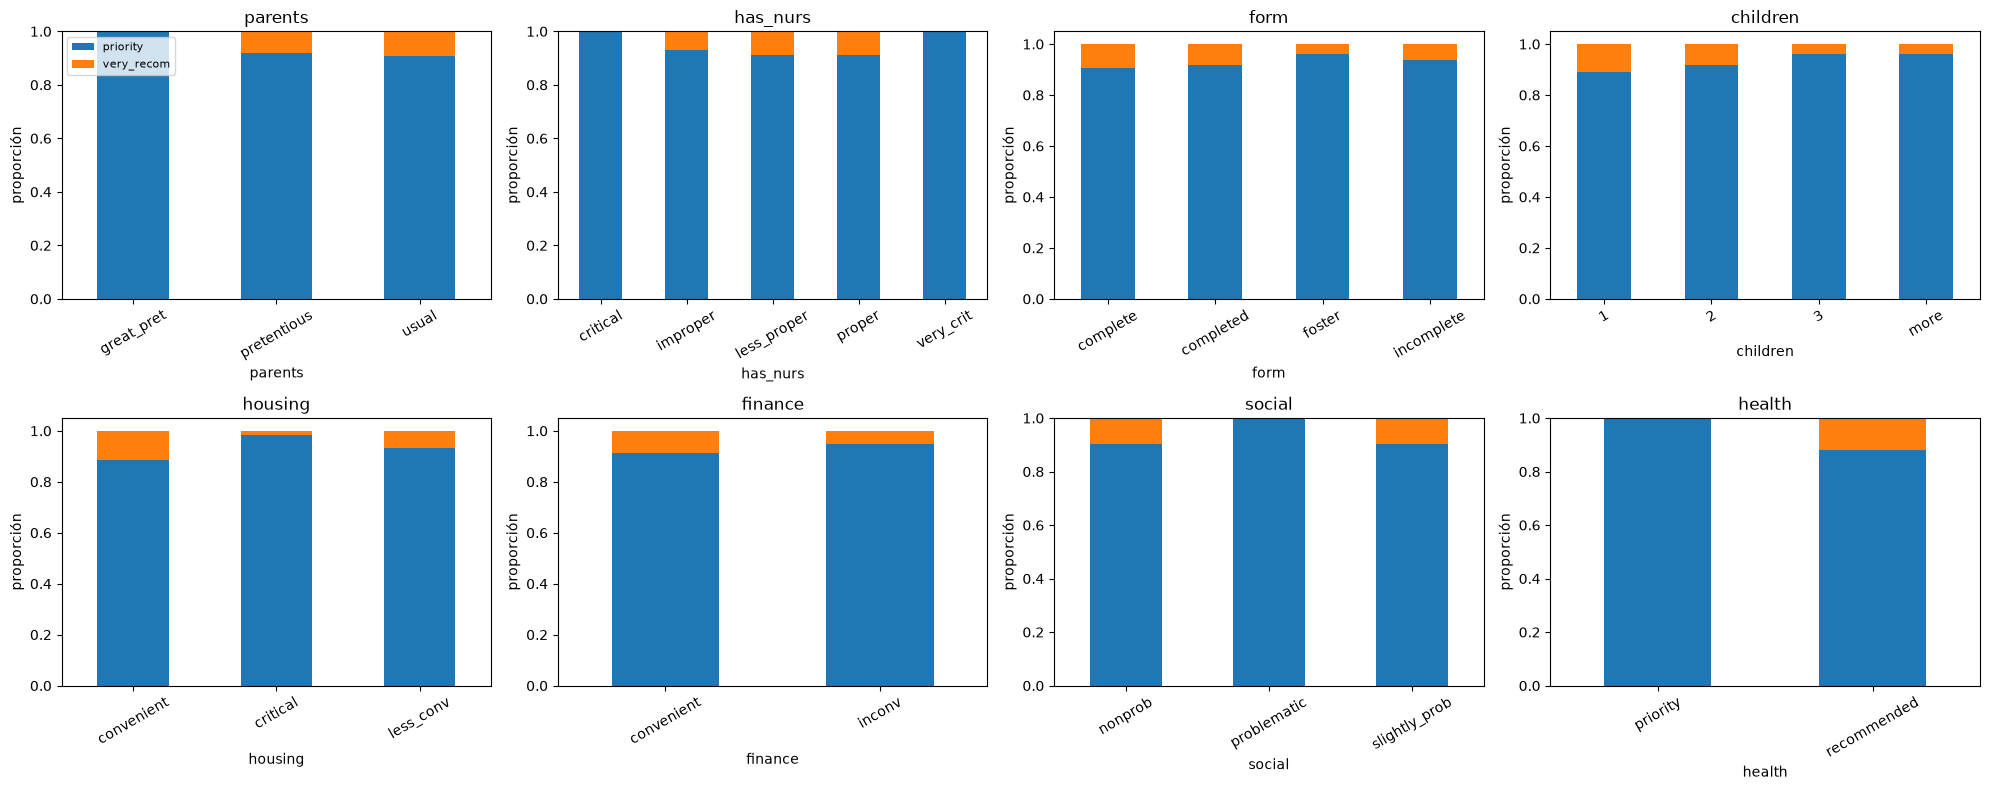

In [135]:
# @title Proporción de "very_recom" para cada valor de cada atributo
fig, axes= plt.subplots(2, 4, figsize=(20, 8))
for col, ax in zip(columnas[:-1], axes.ravel()):
    prop= pd.crosstab(df_bin[col], df_bin['clase'], normalize='index')
    prop.plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_ylabel('proporción')
    ax.tick_params(axis='x', rotation=30)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [136]:
# @title Codificación de atributos
ordinales= {
    'parents':  {'usual': 0, 'pretentious': 1, 'great_pret': 2},
    'has_nurs': {'proper': 0, 'less_proper': 1, 'improper': 2, 'critical': 3, 'very_crit': 4},
    'children': {'1': 1, '2': 2, '3': 3, 'more': 4},
    'housing':  {'convenient': 0, 'less_conv': 1, 'critical': 2},
    'finance':  {'convenient': 0, 'inconv': 1},
    'social':   {'nonprob': 0, 'slightly_prob': 1, 'problematic': 2},
    'health':   {'recommended': 0, 'priority': 1, 'not_recom': 2},
}
df_num= df_bin.copy()
for col, mapa in ordinales.items():
    df_num[col]= df_num[col].map(mapa)

df_num= pd.get_dummies(df_num, columns=['form'], prefix='form', dtype=int)   # one-hot
df_num['clase']= (df_num['clase'] == 'very_recom').astype(int)               # very_recom=1, priority=0

X= df_num.drop('clase', axis=1)
y= df_num['clase']
column_names= X.columns
display(X.head())

# Matriz de correlación
fig= px.imshow(df_num.corr().round(2), text_auto=True, color_continuous_scale='RdBu',
               title='Matriz de Correlación')
fig.update_layout(width=850, height=750)
fig.show()

,parents,has_nurs,children,housing,finance,social,health,form_complete,form_completed,form_foster,form_incomplete
1,0,0,1,0,0,0,1,1,0,0,0
4,0,0,1,0,0,1,1,1,0,0,0
6,0,0,1,0,0,2,0,1,0,0,0
7,0,0,1,0,0,2,1,1,0,0,0
9,0,0,1,0,1,0,0,1,0,0,0


In [137]:
# @title Correlación de cada atributo con la clase
corr_clase= X.corrwith(y).sort_values()
print(corr_clase.round(3))

fig= px.bar(corr_clase, orientation='h',
            title='Correlación de cada atributo con la clase (very_recom = 1)',
            labels={'value': 'correlación', 'index': 'atributo'})
fig.update_layout(showlegend=False)
fig.show()

health            -0.228
housing           -0.154
social            -0.142
parents           -0.118
children          -0.113
has_nurs          -0.103
finance           -0.072
form_foster       -0.067
form_incomplete   -0.018
form_completed     0.029
form_complete      0.052
dtype: float64


In [138]:
# @title Guardar el subconjunto para los puntos siguientes
df_num.to_csv('nursery_priority_vs_very_recom.csv', index=False)
print(f"Guardado: nursery_priority_vs_very_recom.csv ({df_num.shape[0]} filas, {df_num.shape[1]} columnas)")
print("Clase: 1 = very_recom, 0 = priority")

Guardado: nursery_priority_vs_very_recom.csv (4594 filas, 12 columnas)
Clase: 1 = very_recom, 0 = priority


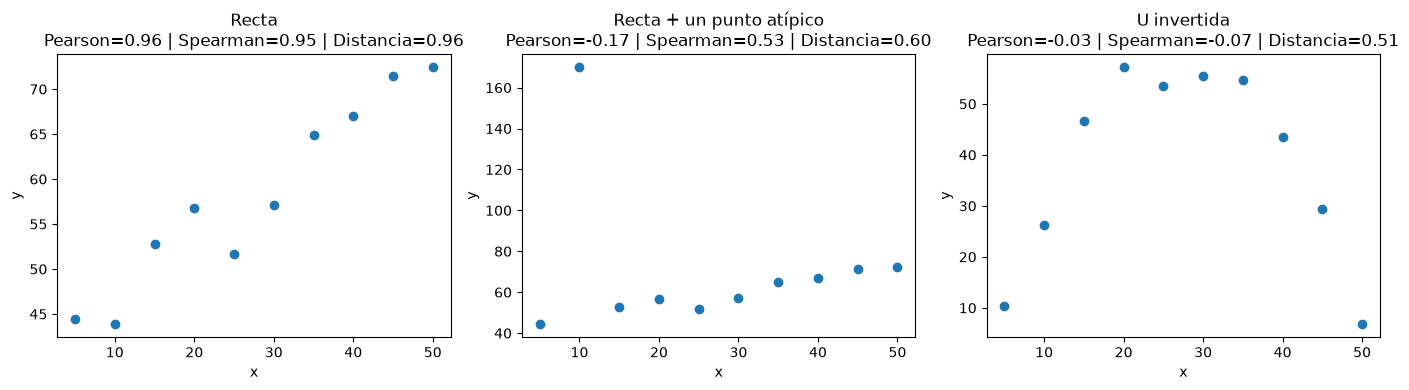

In [139]:
# @title Pearson vs Spearman vs Distancia: datos de ejemplo
from scipy.stats import pearsonr, spearmanr

def corr_distancia(x, y):
    x = np.asarray(x, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    # distancia entre todos los pares de puntos
    a = np.abs(x[:, None] - x)
    b = np.abs(y[:, None] - y)
    # centrado doble: le resta el promedio de filas y columnas
    A = a - a.mean(axis=0) - a.mean(axis=1)[:, None] + a.mean()
    B = b - b.mean(axis=0) - b.mean(axis=1)[:, None] + b.mean()
    return float(np.sqrt((A * B).mean() / np.sqrt((A * A).mean() * (B * B).mean())))

rng = np.random.default_rng(SEMILLA)
x = np.arange(5, 55, 5, dtype=float)
ruido = rng.normal(0, 3, size=x.size)

y_recta = 40 + 0.7 * x + ruido
y_atipico = y_recta.copy()
y_atipico[1] = 170                              # un solo punto atípico
y_curva = -0.1 * (x - 27.5) ** 2 + 60 + ruido   # sube y después baja

casos = {"Recta": y_recta, "Recta + un punto atípico": y_atipico, "U invertida": y_curva}

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, (nombre, y) in zip(ejes, casos.items()):
    r = pearsonr(x, y)[0]
    rho = spearmanr(x, y)[0]
    d = corr_distancia(x, y)
    eje.scatter(x, y)
    eje.set_title(f"{nombre}\nPearson={r:.2f} | Spearman={rho:.2f} | Distancia={d:.2f}")
    eje.set_xlabel("x")
    eje.set_ylabel("y")
plt.tight_layout()
plt.show()

,Pearson,Spearman,Distancia
atributo,,,
health,-0.228,-0.228,0.228
housing,-0.154,-0.154,0.150
social,-0.142,-0.138,0.144
parents,-0.118,-0.110,0.114
children,-0.113,-0.114,0.113
has_nurs,-0.103,-0.092,0.100
form,-0.078,-0.077,0.076
finance,-0.072,-0.072,0.072


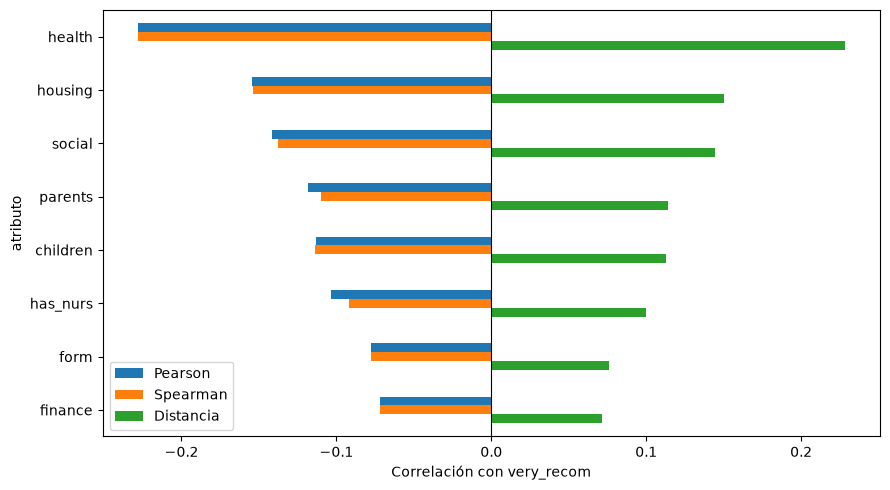

In [140]:
# @title Correlación de cada atributo con very_recom
orden = {
    'parents':  ['usual', 'pretentious', 'great_pret'],
    'has_nurs': ['proper', 'less_proper', 'improper', 'critical', 'very_crit'],
    'form':     ['complete', 'completed', 'incomplete', 'foster'],
    'children': ['1', '2', '3', 'more'],
    'housing':  ['convenient', 'less_conv', 'critical'],
    'finance':  ['convenient', 'inconv'],
    'social':   ['nonprob', 'slightly_prob', 'problematic'],
    'health':   ['recommended', 'priority', 'not_recom'],
}

datos = df[df['clase'].isin(['priority', 'very_recom'])]
# cada categoría pasa a ser su posición en la lista
num = pd.DataFrame({c: datos[c].map({v: i for i, v in enumerate(vals)}) for c, vals in orden.items()})
y = (datos['clase'] == 'very_recom').astype(int)

filas = []
for c in num.columns:
    filas.append({'atributo': c,
                  'Pearson': pearsonr(num[c], y)[0],
                  'Spearman': spearmanr(num[c], y)[0],
                  'Distancia': corr_distancia(num[c], y)})

res = pd.DataFrame(filas).set_index('atributo').sort_values('Distancia', ascending=False)
display(res.round(3))

res.plot.barh(figsize=(9, 5))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Correlación con very_recom")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

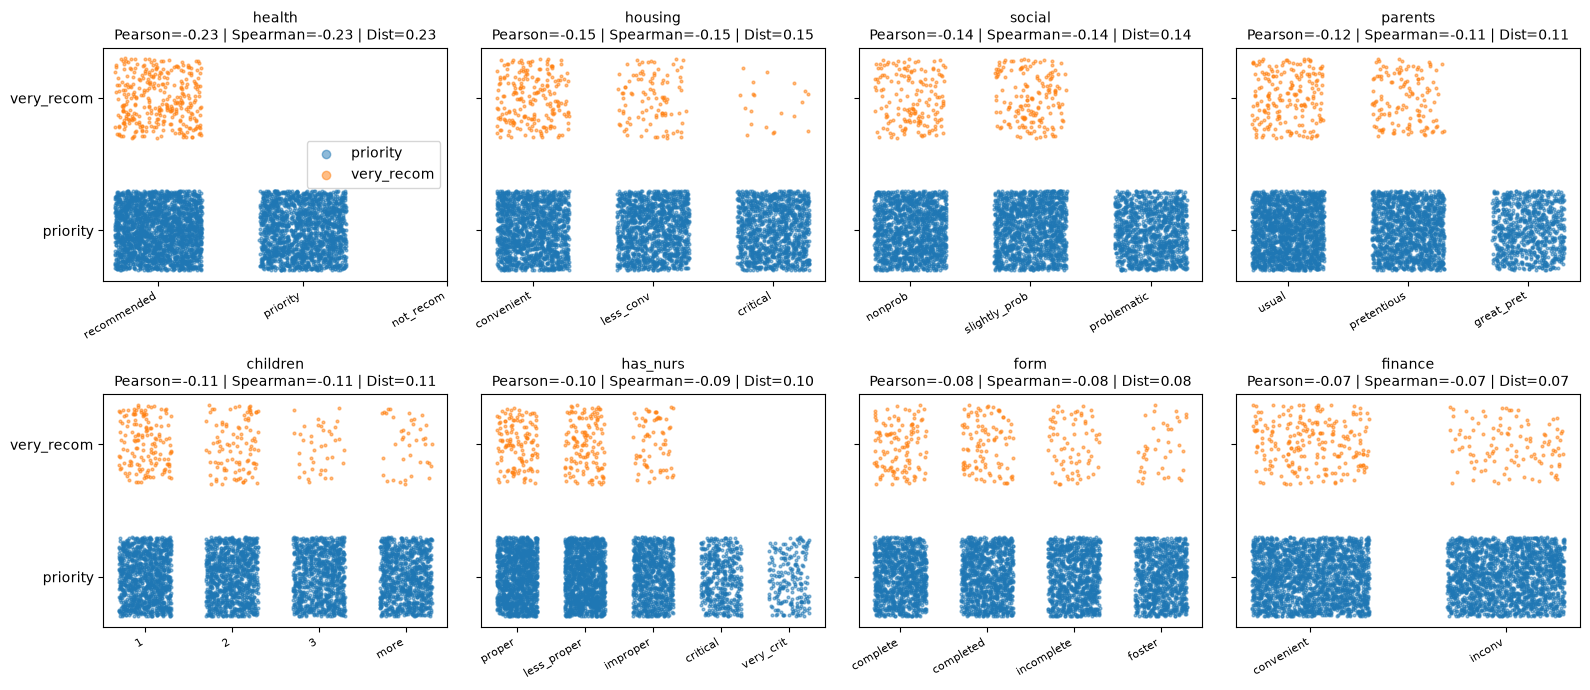

In [141]:
# @title Gráficos de puntos: cada atributo contra la clase
clase_num = (datos['clase'] == 'very_recom').astype(int).to_numpy()
rng = np.random.default_rng(SEMILLA)

fig, ejes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)

for eje, c in zip(ejes.ravel(), res.index):
    # jitter: mueve cada punto un poquito al azar para que no queden todos encimados
    x_jit = num[c].to_numpy() + rng.uniform(-0.3, 0.3, len(num))
    y_jit = clase_num + rng.uniform(-0.3, 0.3, len(num))

    for valor, color, nombre in [(0, 'tab:blue', 'priority'), (1, 'tab:orange', 'very_recom')]:
        filtro = clase_num == valor
        eje.scatter(x_jit[filtro], y_jit[filtro], s=4, alpha=0.5, color=color, label=nombre)

    eje.set_title(f"{c}\nPearson={res.loc[c, 'Pearson']:.2f} | Spearman={res.loc[c, 'Spearman']:.2f} | Dist={res.loc[c, 'Distancia']:.2f}", fontsize=10)
    eje.set_xticks(range(len(orden[c])))
    eje.set_xticklabels(orden[c], rotation=30, ha='right', fontsize=8)
    eje.set_yticks([0, 1])
    eje.set_yticklabels(['priority', 'very_recom'])

ejes[0, 0].legend(markerscale=3, loc='center right')
plt.tight_layout()
plt.show()


In [142]:
# @title Cargar el subconjunto del Punto 1
df_num= pd.read_csv('nursery_priority_vs_very_recom.csv')
X= df_num.drop('clase', axis=1)
y= df_num['clase']          # 1 = very_recom, 0 = priority

print(f"Cantidad de registros: {X.shape[0]}  -  Atributos: {X.shape[1]}")
print(y.value_counts().rename({0: 'priority (0)', 1: 'very_recom (1)'}))
print(f"\nRelación de desbalance: {(y==0).sum() / (y==1).sum():.1f} a 1")

Cantidad de registros: 4594  -  Atributos: 11
clase
priority (0)      4266
very_recom (1)     328
Name: count, dtype: int64

Relación de desbalance: 13.0 a 1


In [143]:
# @title Técnica híbrida: Random OverSampling + Random UnderSampling
over= RandomOverSampler(sampling_strategy=0.5, random_state=SEMILLA)   # very_recom sube hasta el 50% de priority
under= RandomUnderSampler(sampling_strategy=0.8, random_state=SEMILLA) # priority baja hasta que very_recom sea el 80% de priority

X_over, y_over= over.fit_resample(X, y)
X_bal, y_bal= under.fit_resample(X_over, y_over)

comparacion= pd.DataFrame({
    'Original': y.value_counts(),
    'Después de ROS': y_over.value_counts(),
    'Después de ROS + RUS': y_bal.value_counts(),
})
comparacion.index= ['priority (0)', 'very_recom (1)']
display(comparacion)
print(f"Relación final: {(y_bal==0).sum() / (y_bal==1).sum():.2f} a 1")

,Original,Después de ROS,Después de ROS + RUS
priority (0),4266,4266,2666
very_recom (1),328,2133,2133


Relación final: 1.25 a 1


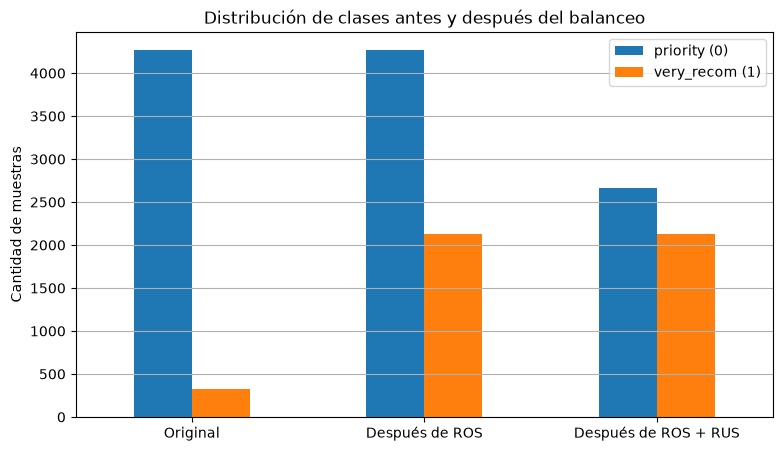

In [144]:
# @title Gráfico: distribución de clases en cada etapa
comparacion.T.plot(kind='bar', figsize=(9, 5), title='Distribución de clases antes y después del balanceo')
plt.ylabel('Cantidad de muestras')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [145]:
# @title ¿Qué hay dentro de la variante balanceada?
df_bal= X_bal.copy()
df_bal['clase']= y_bal.values
df_bal= df_bal[df_num.columns]   # mismo orden de columnas que el original

filas_originales= set(map(tuple, df_num.values))
filas_reales= sum(tuple(f) in filas_originales for f in df_bal.values)
print(f"Filas de la variante balanceada: {len(df_bal)}")
print(f"Filas que existen en el dataset original: {filas_reales}  ->  no se inventó ningún dato")

vr= df_bal[df_bal['clase'] == 1]
pr= df_bal[df_bal['clase'] == 0]
print(f"\nvery_recom: {len(vr)} filas, de las cuales {len(vr.drop_duplicates())} son distintas "
      f"(cada muestra original aparece en promedio {len(vr)/len(vr.drop_duplicates()):.1f} veces)")
print(f"priority:   {len(pr)} filas conservadas de {(y==0).sum()} originales ({len(pr)/(y==0).sum():.0%})")

cols_form= [c for c in X.columns if c.startswith('form_')]
print(f"\nFilas con one-hot de 'form' inválido: {(df_bal[cols_form].sum(axis=1) != 1).sum()}")

Filas de la variante balanceada: 4799
Filas que existen en el dataset original: 4799  ->  no se inventó ningún dato

very_recom: 2133 filas, de las cuales 328 son distintas (cada muestra original aparece en promedio 6.5 veces)
priority:   2666 filas conservadas de 4266 originales (62%)

Filas con one-hot de 'form' inválido: 0


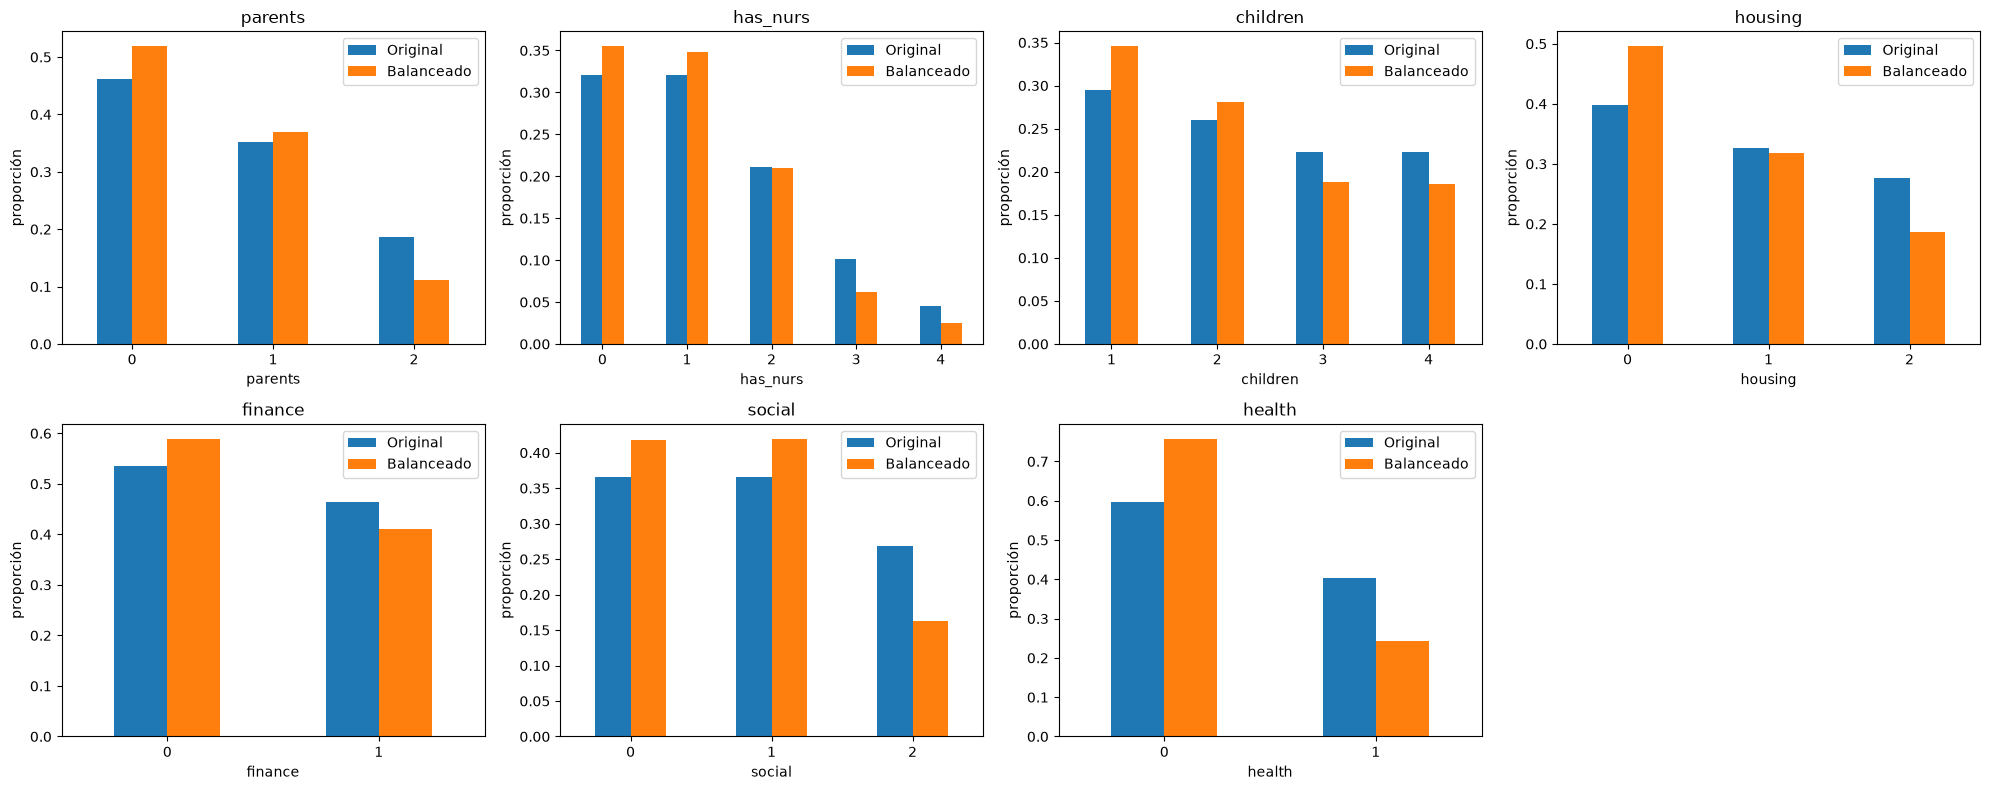

In [146]:
# @title Comparación de la distribución de cada atributo (original vs balanceado)
fig, axes= plt.subplots(2, 4, figsize=(20, 8))
atributos= ['parents', 'has_nurs', 'children', 'housing', 'finance', 'social', 'health']
for col, ax in zip(atributos, axes.ravel()):
    orig= df_num[col].value_counts(normalize=True).sort_index()
    bal= df_bal[col].value_counts(normalize=True).sort_index()
    pd.DataFrame({'Original': orig, 'Balanceado': bal}).plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.set_ylabel('proporción')
    ax.tick_params(axis='x', rotation=0)
axes[1, 3].axis('off')
plt.tight_layout()
plt.show()

In [147]:
# @title Guardar la variante balanceada
df_bal.to_csv('nursery_balanceado_ros_rus.csv', index=False)
print(f"Guardado: nursery_balanceado_ros_rus.csv ({df_bal.shape[0]} filas, {df_bal.shape[1]} columnas)")

Guardado: nursery_balanceado_ros_rus.csv (4799 filas, 12 columnas)


In [148]:
# @title Ejemplo: balancear solo el conjunto de entrenamiento
x_train, x_test, y_train, y_test= train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

x_tr_over, y_tr_over= over.fit_resample(x_train, y_train)
x_tr_bal, y_tr_bal= under.fit_resample(x_tr_over, y_tr_over)

ejemplo= pd.DataFrame({
    'Train original': y_train.value_counts(),
    'Train balanceado': y_tr_bal.value_counts(),
    'Test (sin tocar)': y_test.value_counts(),
})
ejemplo.index= ['priority (0)', 'very_recom (1)']
display(ejemplo)

,Train original,Train balanceado,Test (sin tocar)
priority (0),3413,2132,853
very_recom (1),262,1706,66


In [149]:
# @title Cargar el subconjunto del Punto 1
df_num= pd.read_csv('nursery_priority_vs_very_recom.csv')
X= df_num.drop('clase', axis=1)
y= df_num['clase']          # 1 = very_recom (positiva), 0 = priority
column_names= X.columns

print(f"Cantidad de registros: {X.shape[0]}  -  Atributos: {X.shape[1]}")
print(y.value_counts().rename({0: 'priority (0)', 1: 'very_recom (1)'}))

Cantidad de registros: 4594  -  Atributos: 11
clase
priority (0)      4266
very_recom (1)     328
Name: count, dtype: int64


In [150]:
# @title Función para evaluar un modelo con cross-validation
cv= StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=SEMILLA)
scoring= ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def crear_pipeline(modelo):
    return Pipeline([
        ('over', RandomOverSampler(sampling_strategy=0.5, random_state=SEMILLA)),   # 1º balanceo híbrido (Punto 2)
        ('under', RandomUnderSampler(sampling_strategy=0.8, random_state=SEMILLA)),
        ('scaler', StandardScaler()),                                                # 2º normalización
        ('modelo', modelo)                                                           # 3º modelo
    ])

def evaluar(modelo, nombre):
    res= cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)
    fila= {'Modelo': nombre}
    for m in scoring:
        fila[f'{m} test']= res[f'test_{m}'].mean()
        fila[f'{m} test std']= res[f'test_{m}'].std()
        fila[f'{m} train']= res[f'train_{m}'].mean()
    print(f"{nombre:<42} Acc {fila['accuracy test']:.3f}  Prec {fila['precision test']:.3f}  "
          f"Rec {fila['recall test']:.3f}  F1 {fila['f1 test']:.3f}  AUC {fila['roc_auc test']:.3f}")
    return fila

def tabla_resultados(filas):
    df_res= pd.DataFrame(filas).set_index('Modelo')
    cols= [f'{m} test' for m in scoring]
    return df_res, df_res[cols].round(4)

In [151]:
# @title Cargar el subconjunto del Punto 1
df_num= pd.read_csv('nursery_priority_vs_very_recom.csv')
X= df_num.drop('clase', axis=1)
y= df_num['clase']          # 1 = very_recom (positiva), 0 = priority
column_names= X.columns

print(f"Cantidad de registros: {X.shape[0]}  -  Atributos: {X.shape[1]}")
print(y.value_counts().rename({0: 'priority (0)', 1: 'very_recom (1)'}))

Cantidad de registros: 4594  -  Atributos: 11
clase
priority (0)      4266
very_recom (1)     328
Name: count, dtype: int64


In [152]:
# @title Función para evaluar un modelo con cross-validation
cv= StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=SEMILLA)
scoring= ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def crear_pipeline(modelo):
    return Pipeline([
        ('over', RandomOverSampler(sampling_strategy=0.5, random_state=SEMILLA)),   # 1º balanceo híbrido (Punto 2)
        ('under', RandomUnderSampler(sampling_strategy=0.8, random_state=SEMILLA)),
        ('scaler', StandardScaler()),                                                # 2º normalización
        ('modelo', modelo)                                                           # 3º modelo
    ])

def evaluar(modelo, nombre):
    res= cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)
    fila= {'Modelo': nombre}
    for m in scoring:
        fila[f'{m} test']= res[f'test_{m}'].mean()
        fila[f'{m} test std']= res[f'test_{m}'].std()
        fila[f'{m} train']= res[f'train_{m}'].mean()
    print(f"{nombre:<42} Acc {fila['accuracy test']:.3f}  Prec {fila['precision test']:.3f}  "
          f"Rec {fila['recall test']:.3f}  F1 {fila['f1 test']:.3f}  AUC {fila['roc_auc test']:.3f}")
    return fila

def tabla_resultados(filas):
    df_res= pd.DataFrame(filas).set_index('Modelo')
    cols= [f'{m} test' for m in scoring]
    return df_res, df_res[cols].round(4)

In [153]:
# @title Árbol de decisión - 5 ejecuciones
configs_arbol= {
    'Árbol 1: gini, sin límite':               DecisionTreeClassifier(criterion='gini', random_state=SEMILLA),
    'Árbol 2: entropy, max_depth=3':           DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=SEMILLA),
    'Árbol 3: gini, depth=5, min_leaf=20':     DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_leaf=20, random_state=SEMILLA),
    'Árbol 4: entropy, depth=8, min_split=50': DecisionTreeClassifier(criterion='entropy', max_depth=8, min_samples_split=50, random_state=SEMILLA),
    'Árbol 5: gini, max_leaf_nodes=12':        DecisionTreeClassifier(criterion='gini', max_leaf_nodes=12, random_state=SEMILLA),
}
filas_arbol= [evaluar(m, n) for n, m in configs_arbol.items()]
res_arbol, tabla_arbol= tabla_resultados(filas_arbol)
display(tabla_arbol)

Árbol 1: gini, sin límite                  Acc 0.999  Prec 0.991  Rec 1.000  F1 0.996  AUC 1.000
Árbol 2: entropy, max_depth=3              Acc 0.736  Prec 0.214  Rec 1.000  F1 0.353  AUC 0.858
Árbol 3: gini, depth=5, min_leaf=20        Acc 0.901  Prec 0.417  Rec 0.955  F1 0.580  AUC 0.944
Árbol 4: entropy, depth=8, min_split=50    Acc 0.973  Prec 0.728  Rec 1.000  F1 0.842  AUC 0.992
Árbol 5: gini, max_leaf_nodes=12           Acc 0.964  Prec 0.666  Rec 1.000  F1 0.799  AUC 0.988


,accuracy test,precision test,recall test,f1 test,roc_auc test
Modelo,,,,,
"Árbol 1: gini, sin límite",0.9993,0.9913,1.0000,0.9956,0.9996
"Árbol 2: entropy, max_depth=3",0.7362,0.2144,1.0000,0.3530,0.8579
"Árbol 3: gini, depth=5, min_leaf=20",0.9008,0.4170,0.9545,0.5804,0.9439
"Árbol 4: entropy, depth=8, min_split=50",0.9730,0.7275,1.0000,0.8421,0.9924
"Árbol 5: gini, max_leaf_nodes=12",0.9639,0.6660,1.0000,0.7993,0.9878


In [154]:
# @title KNN - 5 ejecuciones
configs_knn= {
    'KNN 1: K=1, euclidiana':  KNeighborsClassifier(n_neighbors=1),
    'KNN 2: K=3, euclidiana':  KNeighborsClassifier(n_neighbors=3),
    'KNN 3: K=5, euclidiana':  KNeighborsClassifier(n_neighbors=5),
    'KNN 4: K=7, manhattan':   KNeighborsClassifier(n_neighbors=7, metric='manhattan'),
    'KNN 5: K=15, euclidiana': KNeighborsClassifier(n_neighbors=15),
}
filas_knn= [evaluar(m, n) for n, m in configs_knn.items()]
res_knn, tabla_knn= tabla_resultados(filas_knn)
display(tabla_knn)

KNN 1: K=1, euclidiana                     Acc 0.963  Prec 0.697  Rec 0.855  F1 0.767  AUC 0.913
KNN 2: K=3, euclidiana                     Acc 0.943  Prec 0.562  Rec 0.994  F1 0.717  AUC 0.981
KNN 3: K=5, euclidiana                     Acc 0.919  Prec 0.471  Rec 1.000  F1 0.640  AUC 0.982
KNN 4: K=7, manhattan                      Acc 0.879  Prec 0.375  Rec 1.000  F1 0.545  AUC 0.984
KNN 5: K=15, euclidiana                    Acc 0.853  Prec 0.329  Rec 1.000  F1 0.495  AUC 0.993


,accuracy test,precision test,recall test,f1 test,roc_auc test
Modelo,,,,,
"KNN 1: K=1, euclidiana",0.9628,0.6972,0.8545,0.7667,0.9129
"KNN 2: K=3, euclidiana",0.9434,0.5622,0.9939,0.7175,0.9813
"KNN 3: K=5, euclidiana",0.9186,0.4709,1.0000,0.6397,0.9825
"KNN 4: K=7, manhattan",0.8794,0.3746,1.0000,0.5447,0.9838
"KNN 5: K=15, euclidiana",0.8533,0.3292,1.0000,0.4952,0.9927


,accuracy,precision,recall,f1,roc_auc
Árbol de decisión,0.9146,0.6032,0.9909,0.7141,0.9563
KNN,0.9115,0.4868,0.9697,0.6328,0.9706


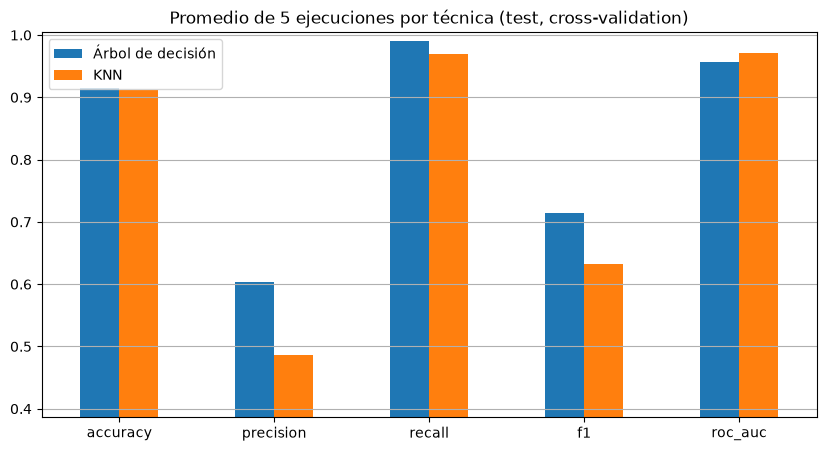

Desviación estándar promedio entre particiones:


,accuracy std,precision std,recall std,f1 std,roc_auc std
Árbol de decisión,0.0057,0.0172,0.0043,0.0139,0.0033
KNN,0.0080,0.0240,0.0126,0.0236,0.0065


In [155]:
# @title Promedio por técnica (test)
promedios= pd.DataFrame({
    'Árbol de decisión': tabla_arbol.mean(),
    'KNN': tabla_knn.mean(),
}).T
promedios.columns= [c.replace(' test', '') for c in promedios.columns]
display(promedios.round(4))

promedios.T.plot(kind='bar', figsize=(10, 5), title='Promedio de 5 ejecuciones por técnica (test, cross-validation)')
plt.ylim(max(0, promedios.values.min() - 0.1), 1.005)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

# Desviación estándar promedio entre particiones (estabilidad)
std_cols= [f'{m} test std' for m in scoring]
estabilidad= pd.DataFrame({
    'Árbol de decisión': res_arbol[std_cols].mean(),
    'KNN': res_knn[std_cols].mean(),
}).T
estabilidad.columns= [c.replace(' test std', ' std') for c in estabilidad.columns]
print("Desviación estándar promedio entre particiones:")
display(estabilidad.round(4))

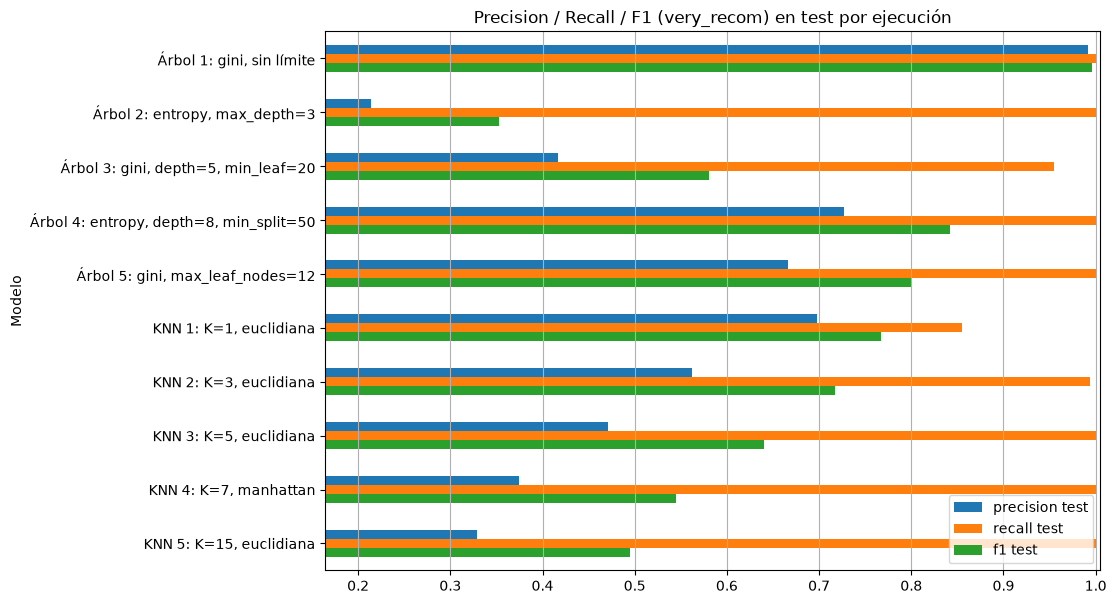

In [156]:
# @title Comparación de las 10 ejecuciones (clase very_recom)
todas= pd.concat([tabla_arbol, tabla_knn])
cols_plot= ['precision test', 'recall test', 'f1 test']
todas[cols_plot].plot(kind='barh', figsize=(10, 7), title='Precision / Recall / F1 (very_recom) en test por ejecución')
plt.xlim(max(0, todas[cols_plot].values.min() - 0.05), 1.005)
plt.grid(axis='x')
plt.gca().invert_yaxis()
plt.show()

In [157]:
# @title Train vs Test: ¿overfitting o underfitting?
todas_res= pd.concat([res_arbol, res_knn])
train_test= pd.DataFrame({
    'F1 train': todas_res['f1 train'],
    'F1 test': todas_res['f1 test'],
    'Diferencia': todas_res['f1 train'] - todas_res['f1 test'],
}).round(4)
display(train_test)

,F1 train,F1 test,Diferencia
Modelo,,,
"Árbol 1: gini, sin límite",0.9989,0.9956,0.0033
"Árbol 2: entropy, max_depth=3",0.3509,0.3530,-0.0022
"Árbol 3: gini, depth=5, min_leaf=20",0.5589,0.5804,-0.0215
"Árbol 4: entropy, depth=8, min_split=50",0.8426,0.8421,0.0005
"Árbol 5: gini, max_leaf_nodes=12",0.7882,0.7993,-0.0111
"KNN 1: K=1, euclidiana",0.9340,0.7667,0.1674
"KNN 2: K=3, euclidiana",0.7922,0.7175,0.0748
"KNN 3: K=5, euclidiana",0.6752,0.6397,0.0355
"KNN 4: K=7, manhattan",0.5781,0.5447,0.0334



***** Mejor configuración (según F1): Árbol 1: gini, sin límite *****
              precision    recall  f1-score   support

    priority       1.00      1.00      1.00       853
  very_recom       1.00      1.00      1.00        66

    accuracy                           1.00       919
   macro avg       1.00      1.00      1.00       919
weighted avg       1.00      1.00      1.00       919



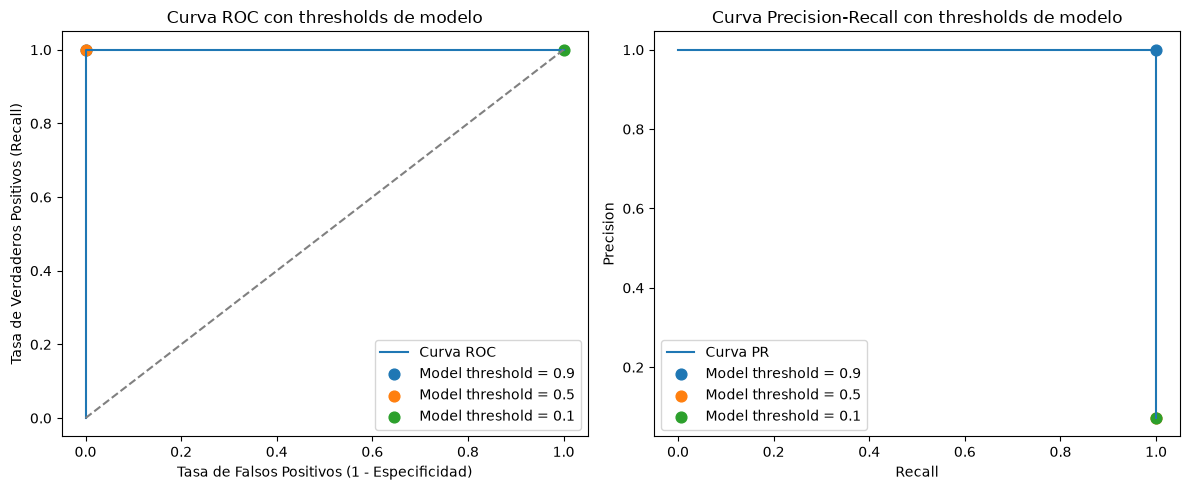


***** Mejor configuración (según F1): KNN 1: K=1, euclidiana *****
              precision    recall  f1-score   support

    priority       0.98      0.98      0.98       853
  very_recom       0.71      0.79      0.75        66

    accuracy                           0.96       919
   macro avg       0.85      0.88      0.86       919
weighted avg       0.96      0.96      0.96       919



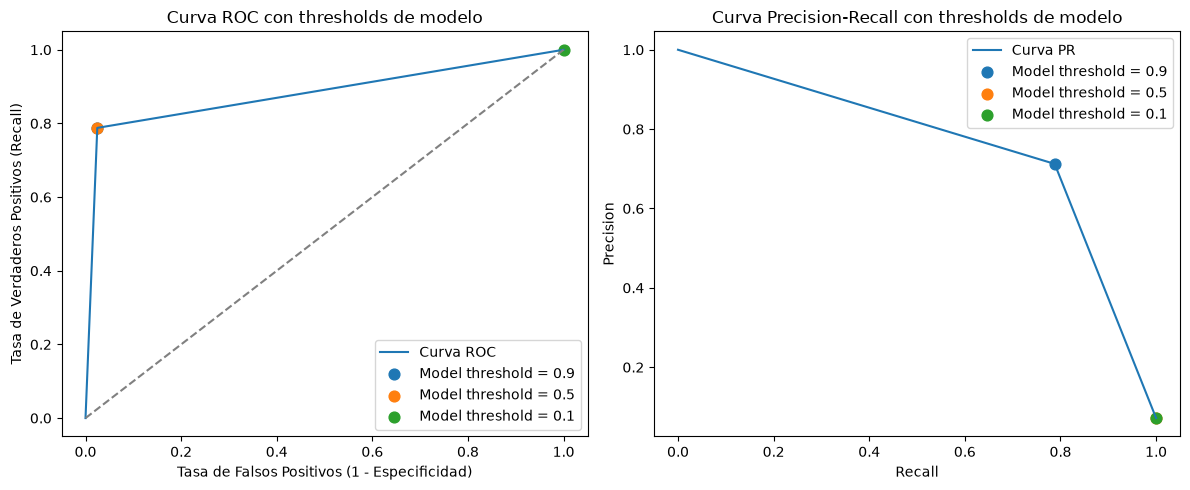

In [158]:
# @title Matriz de confusión y curvas ROC / PR del mejor modelo de cada técnica
x_train, x_test, y_train, y_test= train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)

for res, configs in [(res_arbol, configs_arbol), (res_knn, configs_knn)]:
    mejor= res['f1 test'].idxmax()
    print(f"\n***** Mejor configuración (según F1): {mejor} *****")
    modelo= crear_pipeline(configs[mejor])
    modelo.fit(x_train, y_train)
    y_pred= modelo.predict(x_test)
    print(classification_report(y_test, y_pred, target_names=['priority', 'very_recom']))
    AA_utils.mostrar_matriz_confusion(y_test, y_pred, classes=['priority', 'very_recom'])
    AA_utils.mostrar_curva_roc(modelo, x_test, y_test)


***** Mejor configuración (según F1): Árbol 1: gini, sin límite *****
              precision    recall  f1-score   support

    priority       1.00      1.00      1.00       853
  very_recom       1.00      1.00      1.00        66

    accuracy                           1.00       919
   macro avg       1.00      1.00      1.00       919
weighted avg       1.00      1.00      1.00       919



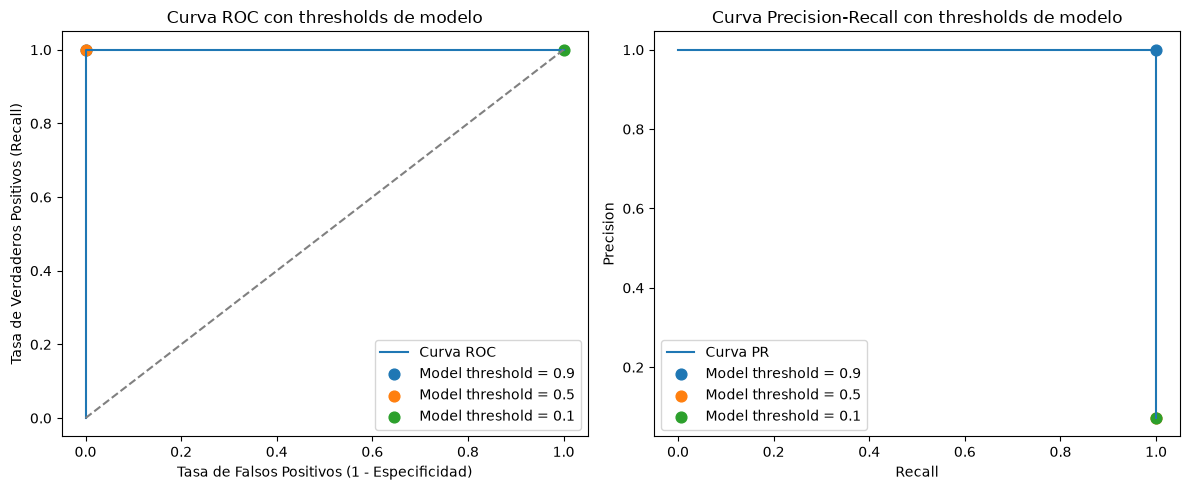


***** Mejor configuración (según F1): KNN 1: K=1, euclidiana *****
              precision    recall  f1-score   support

    priority       0.98      0.98      0.98       853
  very_recom       0.71      0.79      0.75        66

    accuracy                           0.96       919
   macro avg       0.85      0.88      0.86       919
weighted avg       0.96      0.96      0.96       919



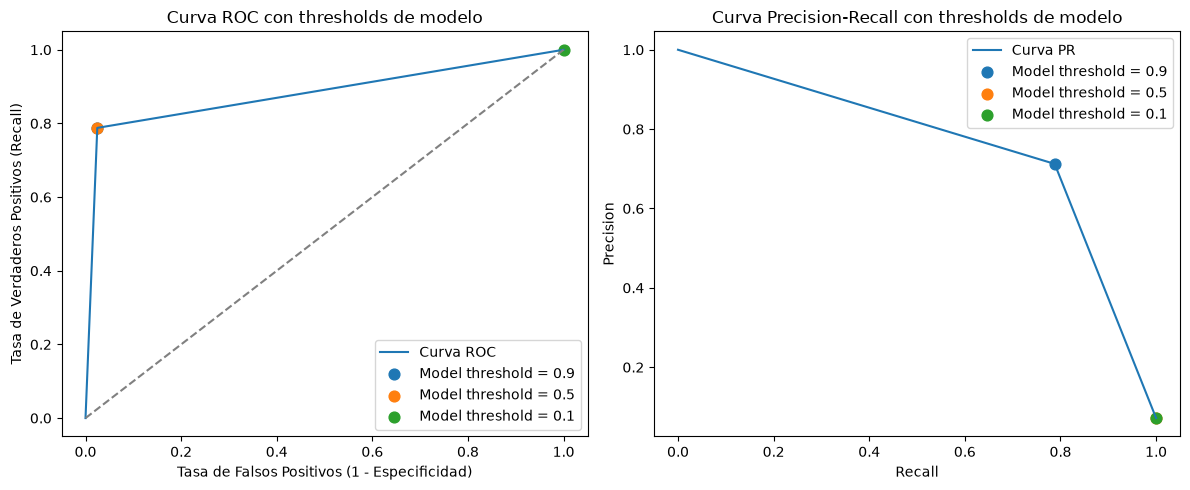

In [159]:
# @title Matriz de confusión y curvas ROC / PR del mejor modelo de cada técnica
x_train, x_test, y_train, y_test= train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)

for res, configs in [(res_arbol, configs_arbol), (res_knn, configs_knn)]:
    mejor= res['f1 test'].idxmax()
    print(f"\n***** Mejor configuración (según F1): {mejor} *****")
    modelo= crear_pipeline(configs[mejor])
    modelo.fit(x_train, y_train)
    y_pred= modelo.predict(x_test)
    print(classification_report(y_test, y_pred, target_names=['priority', 'very_recom']))
    AA_utils.mostrar_matriz_confusion(y_test, y_pred, classes=['priority', 'very_recom'])
    AA_utils.mostrar_curva_roc(modelo, x_test, y_test)

In [160]:
# @title Guardar los resultados para comparar en el Punto 4
pd.concat([res_arbol, res_knn]).to_csv('resultados_punto3.csv')
print("Guardado: resultados_punto3.csv")

Guardado: resultados_punto3.csv


In [161]:
# @title Cargar el subconjunto del Punto 1
df_num= pd.read_csv('nursery_priority_vs_very_recom.csv')
X= df_num.drop('clase', axis=1)
y= df_num['clase']          # 1 = very_recom (positiva), 0 = priority

print(f"Cantidad de registros: {X.shape[0]}  -  Atributos: {X.shape[1]}")
print(y.value_counts().rename({0: 'priority (0)', 1: 'very_recom (1)'}))

Cantidad de registros: 4594  -  Atributos: 11
clase
priority (0)      4266
very_recom (1)     328
Name: count, dtype: int64


In [162]:
# @title Función para evaluar un modelo con cross-validation
cv= StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=SEMILLA)
scoring= ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def crear_pipeline(modelo):
    return Pipeline([
        ('over', RandomOverSampler(sampling_strategy=0.5, random_state=SEMILLA)),   # 1º balanceo híbrido (Punto 2)
        ('under', RandomUnderSampler(sampling_strategy=0.8, random_state=SEMILLA)),
        ('scaler', StandardScaler()),                                                # 2º normalización
        ('modelo', modelo)                                                           # 3º modelo
    ])

def evaluar(modelo, nombre):
    res= cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)
    fila= {'Modelo': nombre}
    for m in scoring:
        fila[f'{m} test']= res[f'test_{m}'].mean()
        fila[f'{m} test std']= res[f'test_{m}'].std()
        fila[f'{m} train']= res[f'train_{m}'].mean()
    print(f"{nombre:<45} Acc {fila['accuracy test']:.3f}  Prec {fila['precision test']:.3f}  "
          f"Rec {fila['recall test']:.3f}  F1 {fila['f1 test']:.3f}  AUC {fila['roc_auc test']:.3f}")
    return fila

def tabla_resultados(filas):
    df_res= pd.DataFrame(filas).set_index('Modelo')
    cols= [f'{m} test' for m in scoring]
    return df_res, df_res[cols].round(4)

In [163]:
# @title Los 10 modelos base
base_learners= [
    ('arbol1', DecisionTreeClassifier(criterion='gini', random_state=SEMILLA)),
    ('arbol2', DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=SEMILLA)),
    ('arbol3', DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_leaf=20, random_state=SEMILLA)),
    ('arbol4', DecisionTreeClassifier(criterion='entropy', max_depth=8, min_samples_split=50, random_state=SEMILLA)),
    ('arbol5', DecisionTreeClassifier(criterion='gini', max_leaf_nodes=12, random_state=SEMILLA)),
    ('knn1', KNeighborsClassifier(n_neighbors=1)),
    ('knn2', KNeighborsClassifier(n_neighbors=3)),
    ('knn3', KNeighborsClassifier(n_neighbors=5)),
    ('knn4', KNeighborsClassifier(n_neighbors=7, metric='manhattan')),
    ('knn5', KNeighborsClassifier(n_neighbors=15)),
]
print(f"Cantidad de modelos base: {len(base_learners)}")

Cantidad de modelos base: 10


In [164]:
# @title Stacking - 5 ejecuciones
configs_stack= {
    'Stacking 1: final=LogReg, cv=5':               StackingClassifier(estimators=base_learners, final_estimator=LogisticRegression(), cv=5),
    'Stacking 2: final=LogReg(C=0.1), passthrough': StackingClassifier(estimators=base_learners, final_estimator=LogisticRegression(C=0.1), cv=5, passthrough=True),
    'Stacking 3: final=Árbol(depth=3), cv=5':       StackingClassifier(estimators=base_learners, final_estimator=DecisionTreeClassifier(max_depth=3, random_state=SEMILLA), cv=5),
    'Stacking 4: final=RandomForest(100), cv=5':    StackingClassifier(estimators=base_learners, final_estimator=RandomForestClassifier(n_estimators=100, random_state=SEMILLA), cv=5),
    'Stacking 5: final=KNN(K=5), cv=3':             StackingClassifier(estimators=base_learners, final_estimator=KNeighborsClassifier(n_neighbors=5), cv=3),
}
filas_stack= [evaluar(m, n) for n, m in configs_stack.items()]
res_stack, tabla_stack= tabla_resultados(filas_stack)
display(tabla_stack)

Stacking 1: final=LogReg, cv=5                Acc 1.000  Prec 0.997  Rec 1.000  F1 0.998  AUC 1.000
Stacking 2: final=LogReg(C=0.1), passthrough  Acc 0.993  Prec 0.913  Rec 1.000  F1 0.954  AUC 1.000
Stacking 3: final=Árbol(depth=3), cv=5        Acc 0.994  Prec 1.000  Rec 0.915  F1 0.954  AUC 0.958
Stacking 4: final=RandomForest(100), cv=5     Acc 0.997  Prec 1.000  Rec 0.964  F1 0.981  AUC 1.000
Stacking 5: final=KNN(K=5), cv=3              Acc 0.997  Prec 1.000  Rec 0.952  F1 0.973  AUC 0.998


,accuracy test,precision test,recall test,f1 test,roc_auc test
Modelo,,,,,
"Stacking 1: final=LogReg, cv=5",0.9998,0.9970,1.0000,0.9985,1.0000
"Stacking 2: final=LogReg(C=0.1), passthrough",0.9930,0.9128,1.0000,0.9541,1.0000
"Stacking 3: final=Árbol(depth=3), cv=5",0.9939,1.0000,0.9152,0.9538,0.9576
"Stacking 4: final=RandomForest(100), cv=5",0.9974,1.0000,0.9636,0.9809,1.0000
"Stacking 5: final=KNN(K=5), cv=3",0.9965,1.0000,0.9515,0.9732,0.9985


In [165]:
# @title Promedio del Stacking (test)
prom_stack= tabla_stack.mean().round(4)
prom_stack.index= [c.replace(' test', '') for c in prom_stack.index]
print("Promedio de las 5 ejecuciones del Stacking:")
display(prom_stack.to_frame('Stacking').T)

Promedio de las 5 ejecuciones del Stacking:


,accuracy,precision,recall,f1,roc_auc
Stacking,0.9961,0.982,0.9661,0.9721,0.9912


In [166]:
# @title Cargar resultados del Punto 3
res_p3= pd.read_csv('resultados_punto3.csv', index_col='Modelo')
res_arbol= res_p3[res_p3.index.str.startswith('Árbol')]
res_knn= res_p3[res_p3.index.str.startswith('KNN')]
cols_test= [f'{m} test' for m in scoring]

Promedio de las 5 ejecuciones de cada técnica (test):


,accuracy,precision,recall,f1,roc_auc
Árbol de decisión,0.9146,0.6033,0.9909,0.7141,0.9563
KNN,0.9115,0.4868,0.9697,0.6327,0.9706
Stacking,0.9961,0.9820,0.9661,0.9721,0.9912


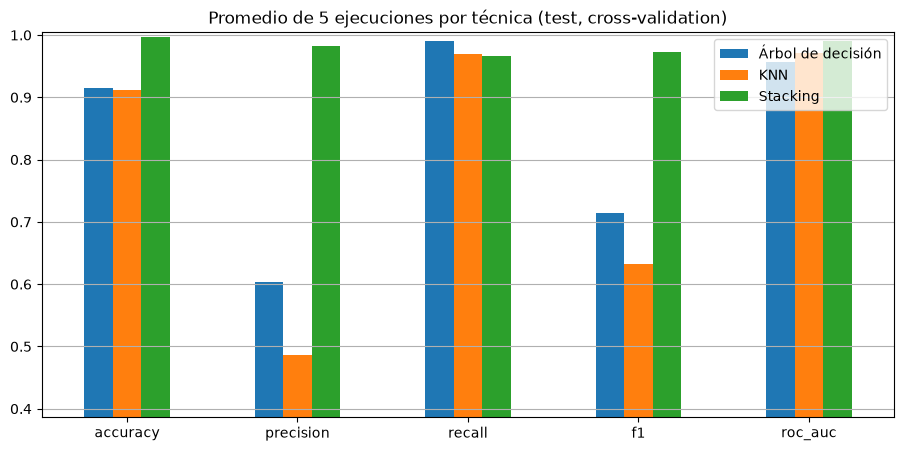

In [167]:
# @title Comparación de promedios: Árbol vs KNN vs Stacking
promedios= pd.DataFrame({
    'Árbol de decisión': res_arbol[cols_test].mean(),
    'KNN': res_knn[cols_test].mean(),
    'Stacking': res_stack[cols_test].mean(),
}).T
promedios.columns= [c.replace(' test', '') for c in promedios.columns]
print("Promedio de las 5 ejecuciones de cada técnica (test):")
display(promedios.round(4))

promedios.T.plot(kind='bar', figsize=(11, 5), title='Promedio de 5 ejecuciones por técnica (test, cross-validation)')
plt.ylim(max(0, promedios.values.min() - 0.1), 1.005)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [168]:
# @title Mejor configuración de cada técnica (según F1)
mejores= pd.DataFrame({
    f'Mejor árbol ({res_arbol["f1 test"].idxmax()})':    res_arbol.loc[res_arbol['f1 test'].idxmax(), cols_test],
    f'Mejor KNN ({res_knn["f1 test"].idxmax()})':        res_knn.loc[res_knn['f1 test'].idxmax(), cols_test],
    f'Mejor Stacking ({res_stack["f1 test"].idxmax()})': res_stack.loc[res_stack['f1 test'].idxmax(), cols_test],
}).T
mejores.columns= [c.replace(' test', '') for c in mejores.columns]
display(mejores.astype(float).round(4))

,accuracy,precision,recall,f1,roc_auc
"Mejor árbol (Árbol 1: gini, sin límite)",0.9993,0.9913,1.0000,0.9956,0.9996
"Mejor KNN (KNN 1: K=1, euclidiana)",0.9628,0.6972,0.8545,0.7667,0.9129
"Mejor Stacking (Stacking 1: final=LogReg, cv=5)",0.9998,0.9970,1.0000,0.9985,1.0000


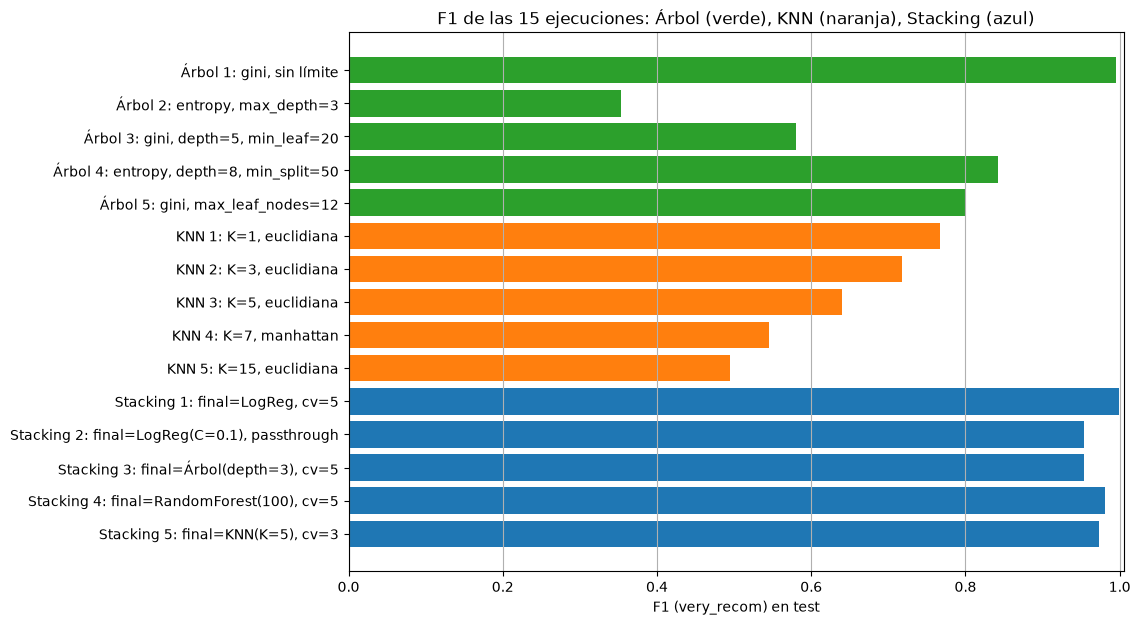

In [169]:
# @title Comparación de las 15 ejecuciones (F1 de very_recom)
todas= pd.concat([res_arbol, res_knn, res_stack])
colores= ['tab:green'] * len(res_arbol) + ['tab:orange'] * len(res_knn) + ['tab:blue'] * len(res_stack)
plt.figure(figsize=(10, 7))
plt.barh(todas.index, todas['f1 test'], color=colores)
plt.xlabel('F1 (very_recom) en test')
plt.title('F1 de las 15 ejecuciones: Árbol (verde), KNN (naranja), Stacking (azul)')
plt.xlim(0, 1.005)
plt.grid(axis='x')
plt.gca().invert_yaxis()
plt.show()

In [170]:
# @title Estabilidad y Train vs Test
std_cols= [f'{m} test std' for m in scoring]
estabilidad= pd.DataFrame({
    'Árbol de decisión': res_arbol[std_cols].mean(),
    'KNN': res_knn[std_cols].mean(),
    'Stacking': res_stack[std_cols].mean(),
}).T
estabilidad.columns= [c.replace(' test std', ' std') for c in estabilidad.columns]
print("Desviación estándar promedio entre particiones:")
display(estabilidad.round(4))

train_test= pd.DataFrame({
    'F1 train': res_stack['f1 train'],
    'F1 test': res_stack['f1 test'],
    'Diferencia': res_stack['f1 train'] - res_stack['f1 test'],
}).round(4)
print("\nStacking - F1 en train vs test:")
display(train_test)

Desviación estándar promedio entre particiones:


,accuracy std,precision std,recall std,f1 std,roc_auc std
Árbol de decisión,0.0057,0.0172,0.0043,0.0139,0.0033
KNN,0.0080,0.0240,0.0126,0.0236,0.0065
Stacking,0.0036,0.0078,0.0413,0.0271,0.0086



Stacking - F1 en train vs test:


,F1 train,F1 test,Diferencia
Modelo,,,
"Stacking 1: final=LogReg, cv=5",0.9992,0.9985,0.0007
"Stacking 2: final=LogReg(C=0.1), passthrough",0.9810,0.9541,0.0269
"Stacking 3: final=Árbol(depth=3), cv=5",0.9992,0.9538,0.0454
"Stacking 4: final=RandomForest(100), cv=5",0.9992,0.9809,0.0183
"Stacking 5: final=KNN(K=5), cv=3",0.9992,0.9732,0.0260


***** Mejor configuración (según F1): Stacking 1: final=LogReg, cv=5 *****
              precision    recall  f1-score   support

    priority       1.00      1.00      1.00       853
  very_recom       1.00      1.00      1.00        66

    accuracy                           1.00       919
   macro avg       1.00      1.00      1.00       919
weighted avg       1.00      1.00      1.00       919



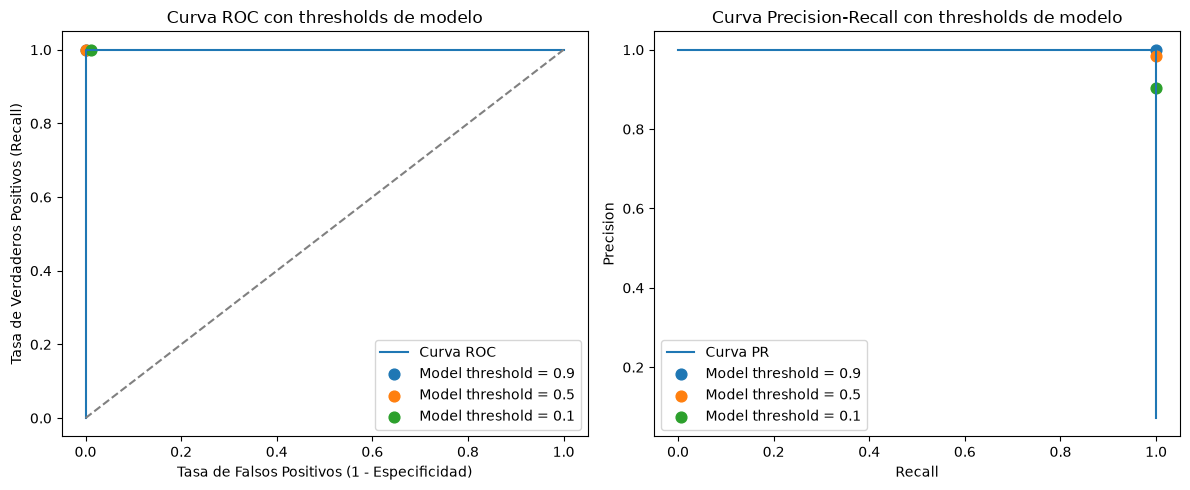

In [171]:
# @title Matriz de confusión y curvas ROC / PR del mejor Stacking
x_train, x_test, y_train, y_test= train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)

mejor_stack= res_stack['f1 test'].idxmax()
print(f"***** Mejor configuración (según F1): {mejor_stack} *****")
modelo= crear_pipeline(configs_stack[mejor_stack])
modelo.fit(x_train, y_train)
y_pred= modelo.predict(x_test)
print(classification_report(y_test, y_pred, target_names=['priority', 'very_recom']))
AA_utils.mostrar_matriz_confusion(y_test, y_pred, classes=['priority', 'very_recom'])
AA_utils.mostrar_curva_roc(modelo, x_test, y_test)